# 03 - Evaluation: Baseline vs Fine-tuned, Error Analysis, and Guardrail

**Goal:** compare the base model (before tuning) with the QLoRA model on the same test data,
analyze failures per complexity category, and show the SQL safety guardrail at work.

**Metrics**
- **Exact match** - normalized SQL identical to the reference.
- **Execution match** - identical execution result on a SQLite database filled with synthetic data matching the schema
  (literals from the query are inserted so that `WHERE` clauses are not automatically empty).
  A stricter variant that only counts cases whose reference result is **non-empty** is reported as well.

**Google Colab:** *Runtime -> Change runtime type -> T4 GPU*. The first cell looks for the project zip (Google Drive, or an upload dialog). Run the cells from top to bottom (*Runtime -> Run all*). Save the notebook together with its outputs: *File -> Download -> Download .ipynb*.
**Kaggle:** Accelerator = T4 GPU (not P100), Internet = On, project added as a Dataset (*Add Input*).

**Adapter** is located automatically (HF repo `<token-username>/qwen2.5-coder-3b-text2sql-qlora`, then `outputs/adapter`) and checked before evaluation. Fill in `adapter` only if you use another repo/folder.

In [1]:
import glob
import os
import sys
from pathlib import Path

try:                                    # detect Google Colab
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

USE_DRIVE = True   # Colab: keep data/results on Google Drive so they survive a disconnected session


def find_project_root():
    """Find the project folder (the one containing src/sql_utils.py): working dir, Kaggle Dataset, or a Colab upload."""
    candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
    candidates += [Path(p).parent.parent for p in glob.glob("/kaggle/input/**/src/sql_utils.py", recursive=True)]
    candidates += [Path(p).parent.parent for p in glob.glob("/content/*/src/sql_utils.py") + glob.glob("/content/*/*/src/sql_utils.py")]
    for c in candidates:
        if (c / "src" / "sql_utils.py").exists():
            return c
    return None


ROOT = find_project_root()
if ROOT is None and IN_COLAB:
    import zipfile
    ZIP_NAME = "Text2SQL_Dwi-Cahyo-Mariyanto.zip"
    # Easiest: put the project zip ONCE in Google Drive (My Drive); this cell finds it by itself, no upload dialog.
    if USE_DRIVE:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            for z in (Path("/content/drive/MyDrive") / ZIP_NAME, Path("/content/drive/MyDrive/Text2SQL") / ZIP_NAME):
                if z.exists():
                    zipfile.ZipFile(z).extractall("/content")
                    print("Project loaded from Google Drive:", z)
                    break
        except Exception as e:                      # fine: fall back to manual upload
            print("Google Drive not used:", type(e).__name__)
        ROOT = find_project_root()
    if ROOT is None:                                # fallback: upload the zip from your computer
        from google.colab import files
        print("Select the file", ZIP_NAME, "from your computer ...")
        for name in files.upload():
            if name.lower().endswith(".zip"):
                zipfile.ZipFile(name).extractall("/content")
        ROOT = find_project_root()
if ROOT is None:
    raise FileNotFoundError(
        "Project folder not found. Colab: run this cell again and upload the project zip. "
        "Kaggle: upload the zip as a Dataset, then 'Add Input'."
    )

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # use a single GPU (safe on T4 x2)
if IN_COLAB and USE_DRIVE:
    try:
        if not os.path.ismount("/content/drive"):
            from google.colab import drive
            drive.mount("/content/drive")
        os.environ["T2S_WORK_DIR"] = "/content/drive/MyDrive/Text2SQL_Dwi-Cahyo-Mariyanto"
    except Exception as e:                          # fine: results are kept locally in the Colab session
        print("Google Drive not mounted, results are kept locally in this session:", type(e).__name__)
for sub in ("src", "Fine-tuning_submission", "Evaluation_submission", "Interface_submission"):
    sys.path.insert(0, str(ROOT / sub))
print("Project root:", ROOT)
if IN_COLAB:
    import torch
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT ACTIVE -> Runtime > Change runtime type > T4 GPU")

Mounted at /content/drive
Select the file Text2SQL_Dwi-Cahyo-Mariyanto.zip from your computer ...


Saving Text2SQL_Dwi-Cahyo-Mariyanto-final.zip to Text2SQL_Dwi-Cahyo-Mariyanto-final.zip
Project root: /content/Text2SQL_Dwi-Cahyo-Mariyanto
GPU: Tesla T4


In [2]:
%pip install -q unsloth  # [Kaggle/Colab] skip if already installed

## 1. Configuration

In [3]:
CONFIG = {
    "base_model": "unsloth/Qwen2.5-Coder-3B-Instruct-bnb-4bit",
    "adapter": "",               # empty = automatic; or "HF-username/repo" / adapter folder path
    "hub_repo_name": "qwen2.5-coder-3b-text2sql-qlora",
    "max_seq_length": 512,
    "batch_size": 16,
    "max_new_tokens": 128,
}

**Hugging Face token (manual):** run the token cell below. If `HF_TOKEN` is not found in Secrets, a hidden input box appears: paste your token (*Write* permission for notebook 02, *Read* is enough for 03/04) and press Enter. Never write the token into a cell; keep `HF_TOKEN_MANUAL` empty before sharing the notebook.

In [4]:
from eval_utils import ensure_hf_token, resolve_adapter

HF_TOKEN_MANUAL = ""   # optional; leave empty to be asked through a hidden input box
HF_TOKEN = ensure_hf_token(HF_TOKEN_MANUAL)
CONFIG["adapter"] = resolve_adapter(CONFIG, HF_TOKEN)   # make sure the adapter really exists before evaluating
print("Adapter in use:", CONFIG["adapter"])

Tempel HF_TOKEN (izin Write) lalu Enter: ··········
Logged in to Hugging Face as: dwicahyom16
Adapter in use: dwicahyom16/qwen2.5-coder-3b-text2sql-qlora


## 2. Run the evaluation **[GPU]**
Baseline predictions from notebook 01 are reused if available; otherwise they are created now. The test data is identical (same seed).

In [5]:
import importlib.util
import json
import pandas as pd
from eval_utils import get_work_dir

# loaded via an explicit path: the name 'evaluate' clashes with the Hugging Face 'evaluate' package on Kaggle
_spec = importlib.util.spec_from_file_location("t2s_evaluate", ROOT / "Evaluation_submission" / "evaluate.py")
t2s_evaluate = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(t2s_evaluate)

RES_DIR = get_work_dir() / "results"
all_metrics = t2s_evaluate.run_evaluation(CONFIG)

[baseline] using saved predictions: baseline_predictions.jsonl
[finetuned] using saved predictions: finetuned_predictions.jsonl


## 3. Results table: before vs after fine-tuning

In [6]:
from IPython.display import Markdown
Markdown((RES_DIR / "results_table.md").read_text(encoding="utf-8"))

| Metric | Baseline (before tuning) | Fine-tuned (QLoRA) |
|---|---|---|
| Number of test examples | 300 | 300 |
| Exact match (normalized) | 49.7% | 75.3% |
| Execution match (synthetic data) | 46.6% | 86.2% |
| Execution match (non-empty gold result) | 45.6% | 86.7% |
| Prediction execution error rate | 4.0% | 0.0% |

**By complexity category (execution match):**

| Category | Baseline (before tuning) (n) | Fine-tuned (QLoRA) (n) |
|---|---|---|
| simple | 44.2% (217) | 86.1% (217) |
| aggregation | 50.6% (79) | 87.0% (79) |
| join | 100.0% (4) | 75.0% (4) |
| nested | - | - |


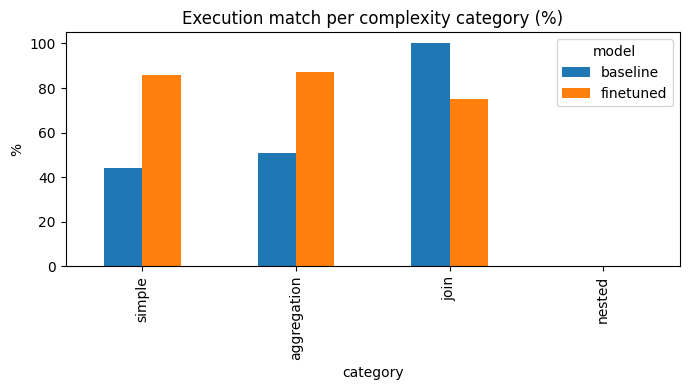

In [7]:
import matplotlib.pyplot as plt
from sql_utils import CATEGORIES

rows = []
for name, m in all_metrics.items():
    for cat in CATEGORIES:
        c = m["by_category"].get(cat)
        if c and c["execution_match"] is not None:
            rows.append({"model": name, "category": cat, "execution_match": c["execution_match"] * 100})
df = pd.DataFrame(rows).pivot(index="category", columns="model", values="execution_match").reindex(CATEGORIES)
ax = df.plot(kind="bar", figsize=(7, 4), title="Execution match per complexity category (%)")
ax.set_ylabel("%"); plt.tight_layout()
plt.savefig(RES_DIR / "execution_match_by_category.png", dpi=150); plt.show()

## 4. Error analysis
Real failure examples per category (suspected causes come from an automatic heuristic, not a manual review).

In [8]:
print((RES_DIR / "error_analysis.md").read_text(encoding="utf-8")[:4000])

# Error Analysis - fine-tuned model

The examples below are taken automatically from real predictions; the 'Likely cause' line is a heuristic, not a manual judgment.

## simple (30 failed out of 217)

**Question:** What score in the final had a tournament of $25,000 Glasgow, Great Britain?
- Schema: `CREATE TABLE table_name_82 (score_in_the_final VARCHAR, tournament VARCHAR)`
- Reference: `select score_in_the_final from table_name_82 where tournament='$25,000 glasgow,great britain'`
- Prediction: `select score_in_the_final from table_name_82 where tournament='$25,000 gosport,great britain'`
- Likely cause: Similar structure, but the columns/values/aggregation differ from the reference.

**Question:** 4tab of commercial broadcaster Radio Tab broadcasts at what frequency?
- Schema: `CREATE TABLE table_name_75 (frequency VARCHAR, callsign VARCHAR, purpose VARCHAR, on_air_id VARCHAR)`
- Reference: `select frequency from table_name_75 where purpose='commercial' and on_air_id='radio tab' and

## 5. SQL safety guardrail (CPU)
Only `SELECT`/`WITH` pass. DDL/DML, multi-statement input, and invalid syntax are rejected.
At execution time the connection also gets a read-only *authorizer* plus row and time limits as a second layer.

In [9]:
import sqlite3
from guardrail import validate_sql
from sql_utils import build_sqlite_db

schema = "CREATE TABLE city (name VARCHAR, population INTEGER)"
conn = build_sqlite_db(schema)
tests = [
    "SELECT name FROM city WHERE population > 5",
    "SELECT COUNT(*) FROM city;",
    "DROP TABLE city",
    "DELETE FROM city WHERE population < 5",
    "UPDATE city SET population = 0",
    "SELECT * FROM city; DROP TABLE city",
    "SELECT wrong_column_name FROM city",
    "SELECT name FROM city WHERE name = 'drop table x'",
]
pd.DataFrame([{"sql": s, "allowed": (r := validate_sql(s, conn=conn)).allowed, "reason": r.reason} for s in tests])

,sql,allowed,reason
0,SELECT name FROM city WHERE population > 5,True,Safe: read-only query (SELECT).
1,SELECT COUNT(*) FROM city;,True,Safe: read-only query (SELECT).
2,DROP TABLE city,False,Only SELECT queries are allowed.
3,DELETE FROM city WHERE population < 5,False,Only SELECT queries are allowed.
4,UPDATE city SET population = 0,False,Only SELECT queries are allowed.
5,SELECT * FROM city; DROP TABLE city,False,Only one SQL statement is allowed.
6,SELECT wrong_column_name FROM city,False,Invalid syntax or schema: no such column: wron...
7,SELECT name FROM city WHERE name = 'drop table x',True,Safe: read-only query (SELECT).


## 6. Inference examples with output
The first ten test examples from the fine-tuned model.

In [10]:
recs = [json.loads(l) for l in open(RES_DIR / "finetuned_predictions.jsonl", encoding="utf-8")]
for r in recs[:10]:
    print("Q    :", r["question"]); print("GOLD :", r["answer"]); print("PRED :", r["pred"], "| exec_match =", r["exec_match"], "\n")

Q    : How many cities are there in state "Colorado"?
GOLD : SELECT COUNT(*) FROM addresses WHERE state_province_county = "Colorado"
PRED : SELECT COUNT(*) FROM addresses WHERE state_province_county = "Colorado" | exec_match = True 

Q    : What is the duration that has 3 for appearances, and james garret as the character?
GOLD : SELECT duration FROM table_name_20 WHERE appearances = "3" AND character = "james garret"
PRED : SELECT duration FROM table_name_20 WHERE appearances = "3" AND character = "james garret" | exec_match = True 

Q    : Tell me the sum of Grid for giancarlo fisichella
GOLD : SELECT SUM(grid) FROM table_name_84 WHERE driver = "giancarlo fisichella"
PRED : SELECT SUM(grid) FROM table_name_84 WHERE driver = "giancarlo fisichella" | exec_match = True 

Q    : What general classification has 4 as the stage?
GOLD : SELECT general_classification FROM table_name_96 WHERE stage = "4"
PRED : SELECT general_classification FROM table_name_96 WHERE stage = "4" | exec_match = T

## Save results
In Colab, a zip archive is downloaded to your computer automatically; on Kaggle it appears in the Output tab after *Save Version*.

In [11]:
from eval_utils import export_results

export_results(RES_DIR)

Results archive: /content/drive/MyDrive/Text2SQL_Dwi-Cahyo-Mariyanto/outputs/text2sql_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/drive/MyDrive/Text2SQL_Dwi-Cahyo-Mariyanto/outputs/text2sql_results.zip')

## 7. Summary & next steps
- Copy the contents of `outputs/results/` into the project's `Evaluation_submission/results/` folder.
- Run `python Evaluation_submission/evaluate.py --fill-docs` to write the results table into `REPORT.md`, `README.md`, and `MODEL_CARD.md`.
- **Next:** `Interface_submission/04_interface_demo.ipynb`.